In [1]:
!python -m pip install pandas numpy scikit-learn matplotlib seaborn ucimlrepo joblib streamlit

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)

In [3]:
dataset=fetch_ucirepo(id=320)

X=dataset.data.features.copy()
y=dataset.data.targets['G3'].copy()

print('Datset loaded successfully')
print('\nInput Features:')
print(X.head())

print('\nFinal Grades:')
print(y.head())

Datset loaded successfully

Input Features:
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  higher internet  romantic  famrel  freetime goout Dalc Walc health absences  
0    yes       no        no       4         3     4    1    1      3        4  
1    yes      yes        no       5         3     3    1    1      3        2  
2    yes      yes        no       4         3     2    2    3      3        6  
3    yes      yes       yes       3         2     2    1    1      5        0  
4    yes       no        no       4         3     2    1    2      5 

In [4]:
print("Dataset Shape:", X.shape)

print("\nColumn Names:")
print(X.columns.tolist())

print("\nMissing Values:")
print(X.isnull().sum())

print("\nTarget Summary:")
print(y.describe())

Dataset Shape: (649, 30)

Column Names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Missing Values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
dtype: int64

Target Summary:
count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%

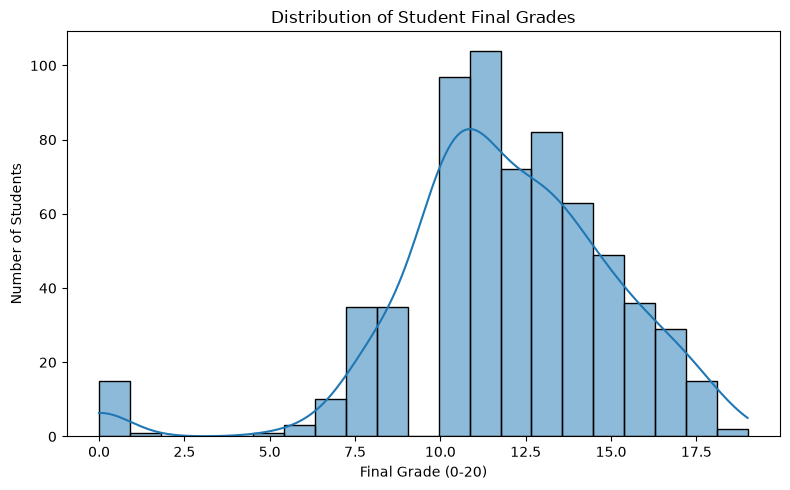

In [5]:
plt.figure(figsize=(8,5))

sns.histplot(y, bins=21, kde=True)

plt.title("Distribution of Student Final Grades")
plt.xlabel("Final Grade (0-20)")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

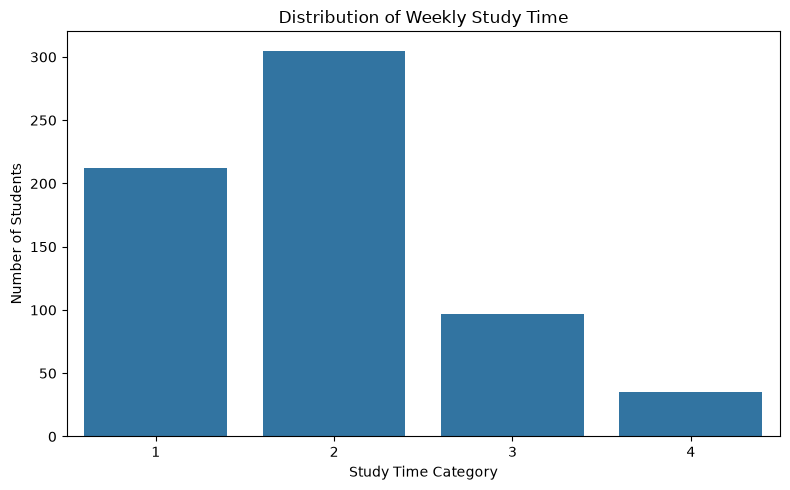

In [6]:
plt.figure(figsize=(8,5))

sns.countplot(data=X, x="studytime")

plt.title("Distribution of Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

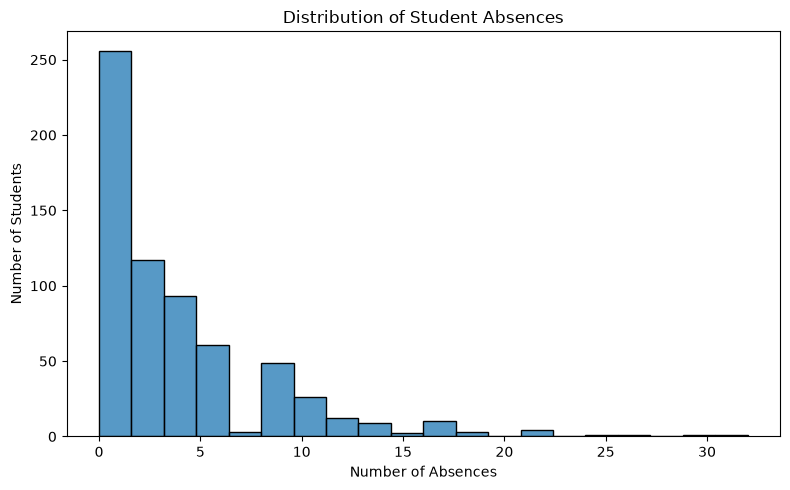

In [7]:
plt.figure(figsize=(8,5))

sns.histplot(data=X, x="absences", bins=20)

plt.title("Distribution of Student Absences")
plt.xlabel("Number of Absences")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [8]:
features=["age","studytime","failures","absences","schoolsup","famsup","paid","activities","internet","health","goout","freetime"]
X=X[features].copy()
y=(y<10).astype(int)

print("Selected FEatures:")
print(X.head())

print("\nTarget Classes:")
print(y.value_counts().rename(index={0 : "Not currently flagged", 1 : "Needs support"}))

Selected FEatures:
   age  studytime  failures  absences schoolsup famsup paid activities  \
0   18          2         0         4       yes     no   no         no   
1   17          2         0         2        no    yes   no         no   
2   15          2         0         6       yes     no   no         no   
3   15          3         0         0        no    yes   no        yes   
4   16          2         0         0        no    yes   no         no   

  internet  health  goout  freetime  
0       no       3      4         3  
1      yes       3      3         3  
2      yes       3      2         3  
3      yes       5      2         2  
4       no       5      2         3  

Target Classes:
G3
Not currently flagged    549
Needs support            100
Name: count, dtype: int64


In [9]:
numerical_features=["age","studytime","failures","absences","health","goout","freetime"]
categorical_features=["schoolsup","famsup","paid","activities","internet"]

print("Numerical features:", numerical_features)
print("Categoricfal features:", categorical_features)

Numerical features: ['age', 'studytime', 'failures', 'absences', 'health', 'goout', 'freetime']
Categoricfal features: ['schoolsup', 'famsup', 'paid', 'activities', 'internet']


In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 519
Testing records: 130


In [11]:
preprocessor = ColumnTransformer(transformers=[("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)], remainder="passthrough")
model=Pipeline(steps=[("preprocessor", preprocessor), ("classifier", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=3, 
                                                                                            class_weight="balanced", random_state=42))])
print("ML pipeline created successfully!")

ML pipeline created successfully!


In [12]:
model.fit(X_train, y_train)
print("Model training completed!")

Model training completed!


In [13]:
y_pred=model.predict(X_test)
y_probability=model.predict_proba(X_test)[:,1]

accuracy=accuracy_score(y_test, y_pred)
print("Model Accuracy:", round(accuracy*100, 2),"%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=[0,1], target_names=["Not currently flagged","Needs support"], zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, y_probability),3))

Model Accuracy: 79.23 %

Classification Report:
                       precision    recall  f1-score   support

Not currently flagged       0.88      0.87      0.88       110
        Needs support       0.33      0.35      0.34        20

             accuracy                           0.79       130
            macro avg       0.61      0.61      0.61       130
         weighted avg       0.80      0.79      0.79       130

ROC-AUC: 0.68


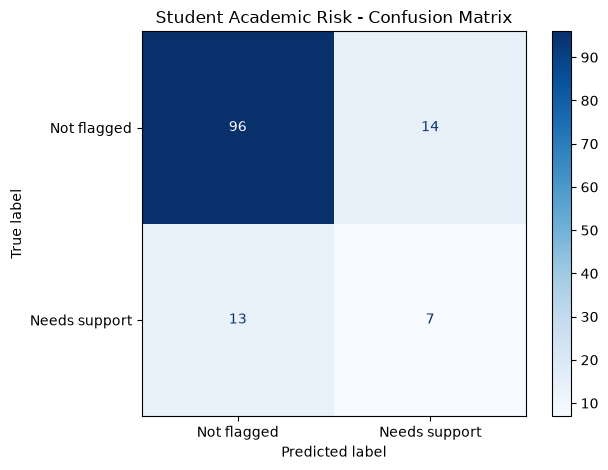

In [14]:
cm=confusion_matrix(y_test, y_pred, labels=[0,1])
display=ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Not flagged","Needs support"])
display.plot(cmap="Blues", values_format="d")

plt.title("Student Academic Risk - Confusion Matrix")
plt.tight_layout()
plt.show()

In [15]:
fitted_preprocessor=model.named_steps["preprocessor"]

encoded_names=(fitted_preprocessor.named_transformers_["categorical"].get_feature_names_out(categorical_features))
all_feature_names=list(encoded_names)+numerical_features

importances=(model.named_steps["classifier"].feature_importances_)
importance_df=pd.DataFrame({"Feature":all_feature_names,"Importance":importances})
importance_df=importance_df.sort_values(by="Importance",ascending=False)
print(importance_df.head(10))

          Feature  Importance
12       failures    0.282188
13       absences    0.116863
11      studytime    0.108551
15          goout    0.095671
10            age    0.084096
16       freetime    0.076685
14         health    0.066467
6   activities_no    0.030184
3      famsup_yes    0.026032
2       famsup_no    0.024041


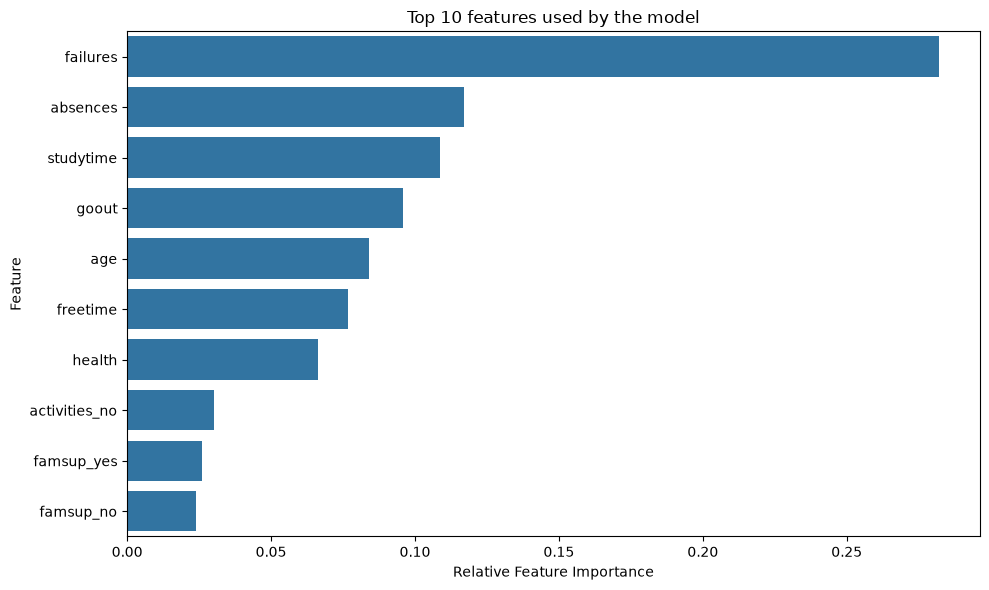

In [16]:
plt.figure(figsize=(10,6))

sns.barplot(data=importance_df.head(10), x="Importance", y="Feature")

plt.title("Top 10 features used by the model") 
plt.xlabel("Relative Feature Importance")
plt.ylabel("Feature") 
plt.tight_layout() 
plt.show()

In [17]:
def generate_recommendations(student):
    recommendations=[]
    if student['studytime']<=2:
        recommendations.append("Create a consistent study timetable and increase study time.")
    if student['absences']>=10:
        recommendations.append("Review missed lessons and discuss attendance barriers with a teacher.")
    if student['schoolsup']=="no":
        recommendations.append("Consider discussing available academic support with the school.")
    if student['famsup']=="no":
        recommendations.append("Consider finding a study partner, mentor and a supportive learning environment.")
    if student['internet']=="no":
        recommendations.append("Ask the school about library facilities, offline study materials or computer access.")
    if student['health']<=2:
        recommendations.append("Consider seeking appropriate medical healthcare for good physical and mental health.")
    if not recommendations:
        recommendations.append("Continue regular revision, solve sample papers and review progress each week.")
    return recommendations

In [18]:
student={'age':18,'studytime':2,'failures':1,'absences':12,'schoolsup':"no",'famsup':"yes",'paid':"no",'activities':"yes",'internet':"yes",
         'health':3,'goout':3,'freetime':3}
student_df=pd.DataFrame([student], columns=features)
prediction=int(model.predict(student_df)[0])
risk_probability=model.predict_proba(student_df)[0,1]

print("Estimated low-grade probability:", f"{risk_probability:.1%}")

if prediction==1:
    print("Result: May need additional academic support")
else:
    print("Result: Not currently flagged by the model")

print("\nPersonalized recommendations:")
for i, recommendation in enumerate(generate_recommendations(student), start=1):
    print(f"{i}.{recommendation}")

Estimated low-grade probability: 62.9%
Result: May need additional academic support

Personalized recommendations:
1.Create a consistent study timetable and increase study time.
2.Review missed lessons and discuss attendance barriers with a teacher.
3.Consider discussing available academic support with the school.


In [19]:
joblib.dump(model, "student_risk_model.pkl")
print("Model saved successfully!")

Model saved successfully!
